<a href="https://colab.research.google.com/github/psaichaitanya-hue/Machine_learning/blob/main/ML_project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 1

In [ ]:
!pip -q install pandas numpy scikit-learn matplotlib torch

Cell 2

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.optim as optim

print("Libraries imported successfully!")
print("PyTorch version:", torch.__version__)

Libraries imported successfully!
PyTorch version: 2.11.0+cpu


Cell 3

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Transmission_Dataset.csv to Transmission_Dataset.csv


cell 4

In [ ]:
df = pd.read_csv("Transmission_Dataset.csv")

print("Dataset shape:", df.shape)

print("\nFrequency channels:")
print(df["Frequency_Channel"].unique())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (10000, 42)

Frequency channels:
[433 915 470 923 868]

Missing values:
0

First 5 rows:


,Device_Type,Environment_Type,Weather_Condition,Distance,Transmission_Power,Frequency_Channel,Packet_Size,Battery_Level,RSSI,SNR,...,Ambient_Humidity,Atmospheric_Pressure,Wind_Speed,Rainfall,Terrain_Obstruction,Node_Density,Network_Congestion,Channel_Switch_Count,Connection_Attempt_Count,Acknowledgment_Rate
0,Smart_Meter,Industrial,Heavy_Rain,19.325,15.98,433,186,43.30,-61.11,14.49,...,57.75,996.57,12.42,4.74,0.927,341.02,42.69,6,5,93.66
1,Tracking_Device,Urban,Clear,14.049,11.90,915,178,30.77,-61.74,18.10,...,95.03,994.19,11.18,2.24,0.794,294.02,27.46,9,4,100.00
2,Environmental_Node,Urban,Clear,28.953,12.53,470,97,99.55,-82.50,9.17,...,68.45,1009.50,16.86,0.59,0.161,117.58,40.83,2,4,99.68
3,Industrial_Node,Rural,Rain,6.960,13.61,470,228,34.35,-37.69,20.00,...,50.70,1003.26,1.28,0.97,0.273,372.43,50.63,4,6,100.00
4,Sensor_Node,Industrial,Cloudy,17.842,14.07,433,236,44.05,-68.73,12.05,...,98.18,994.19,13.94,14.16,0.247,262.11,17.78,1,3,100.00


Cell 5

In [ ]:
STATE_COLUMNS = [
    "Channel_Occupancy",
    "Interference_Power",
    "Interference_Density",
    "Packet_Collision_Rate",
    "Packet_Loss_Rate",
    "Latency",
    "RSSI",
    "SNR",
    "Node_Density",
    "Network_Congestion"
]

ACTION_COLUMN = "Frequency_Channel"

print("State features:", len(STATE_COLUMNS))
print("Action:", ACTION_COLUMN)

State features: 10
Action: Frequency_Channel


Cell 6

In [ ]:
# Convert Delivery_Success to 0/1
df["Success_Binary"] = (
    df["Delivery_Success"].astype(str).str.lower() == "success"
).astype(float)

# Normalize important performance variables
reward_columns = [
    "Data_Rate",
    "Interference_Density",
    "Packet_Loss_Rate",
    "Latency",
    "Energy_Cost",
    "SNR"
]

for col in reward_columns:
    mn = df[col].min()
    mx = df[col].max()
    df[col + "_norm"] = (df[col] - mn) / (mx - mn + 1e-8)

# Reward:
# HIGH data rate + success + SNR
# LOW interference + packet loss + latency + energy

df["Reward"] = (
    0.35 * df["Data_Rate_norm"]
    + 0.20 * df["Success_Binary"]
    + 0.10 * df["SNR_norm"]
    - 0.15 * df["Interference_Density_norm"]
    - 0.10 * df["Packet_Loss_Rate_norm"]
    - 0.05 * df["Latency_norm"]
    - 0.05 * df["Energy_Cost_norm"]
)

print("Reward created successfully!")
print(df["Reward"].describe())

Reward created successfully!
count    10000.000000
mean         0.217551
std          0.171553
min         -0.244630
25%          0.092848
50%          0.222770
75%          0.347111
max          0.611700
Name: Reward, dtype: float64


Cell 7

In [ ]:
df["Success_Binary"]

,Success_Binary
0,0.0
1,1.0
2,1.0
3,0.0
4,1.0
...,...
9995,1.0
9996,0.0
9997,1.0
9998,0.0


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from google.colab import files
uploaded = files.upload()

df = pd.read_csv("Transmission_Dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Saving Transmission_Dataset.csv to Transmission_Dataset.csv
Dataset loaded successfully!
Dataset shape: (10000, 42)


,Device_Type,Environment_Type,Weather_Condition,Distance,Transmission_Power,Frequency_Channel,Packet_Size,Battery_Level,RSSI,SNR,...,Ambient_Humidity,Atmospheric_Pressure,Wind_Speed,Rainfall,Terrain_Obstruction,Node_Density,Network_Congestion,Channel_Switch_Count,Connection_Attempt_Count,Acknowledgment_Rate
0,Smart_Meter,Industrial,Heavy_Rain,19.325,15.98,433,186,43.30,-61.11,14.49,...,57.75,996.57,12.42,4.74,0.927,341.02,42.69,6,5,93.66
1,Tracking_Device,Urban,Clear,14.049,11.90,915,178,30.77,-61.74,18.10,...,95.03,994.19,11.18,2.24,0.794,294.02,27.46,9,4,100.00
2,Environmental_Node,Urban,Clear,28.953,12.53,470,97,99.55,-82.50,9.17,...,68.45,1009.50,16.86,0.59,0.161,117.58,40.83,2,4,99.68
3,Industrial_Node,Rural,Rain,6.960,13.61,470,228,34.35,-37.69,20.00,...,50.70,1003.26,1.28,0.97,0.273,372.43,50.63,4,6,100.00
4,Sensor_Node,Industrial,Cloudy,17.842,14.07,433,236,44.05,-68.73,12.05,...,98.18,994.19,13.94,14.16,0.247,262.11,17.78,1,3,100.00


Cell 8

In [ ]:

# ============================================================
# WIRELESS COMMUNICATION PERFORMANCE METRICS
# ============================================================

# Convert packet-loss percentage to a fraction if needed
loss = df["Packet_Loss_Rate"].astype(float)

if loss.max() > 1:
    loss_fraction = loss / 100.0
else:
    loss_fraction = loss

loss_fraction = loss_fraction.clip(0, 1)

# 1. Successful Throughput
# Data rate adjusted for successful delivery
df["Throughput"] = (
    df["Data_Rate"] * df["Success_Binary"]
)

# 2. Goodput
# Useful data rate after packet losses
df["Goodput"] = (
    df["Data_Rate"] * (1 - loss_fraction)
)

# 3. Packet Error Rate (PER) proxy
# Uses packet loss because direct packet-error counts
# are not available in the dataset
df["PER_Proxy"] = loss_fraction

# 4. Reliability
df["Reliability"] = 1 - loss_fraction

# 5. Spectral Efficiency
# Data_Rate and Bandwidth must use compatible units
df["Spectral_Efficiency"] = (
    df["Data_Rate"] / df["Bandwidth"].replace(0, np.nan)
)

# 6. Energy Efficiency
# Useful throughput per unit of recorded energy cost
df["Energy_Efficiency"] = (
    df["Throughput"] /
    df["Energy_Cost"].replace(0, np.nan)
)

# 7. Shannon capacity estimate
# Assumes SNR is in dB and Bandwidth is in Hz
snr_linear = 10 ** (df["SNR"].astype(float) / 10)

df["Shannon_Capacity_Estimate"] = (
    df["Bandwidth"] * np.log2(1 + snr_linear)
)

# 8. Channel-wise observed data rate
# This is a channel average, not simultaneous multi-user sum rate
df["Channel_Mean_Data_Rate"] = (
    df.groupby("Frequency_Channel")["Data_Rate"]
      .transform("mean")
)

# Report standard wireless communication metrics
wireless_metrics = [
    "Latency",
    "Jitter",
    "Data_Rate",
    "Throughput",
    "Goodput",
    "PER_Proxy",
    "Reliability",
    "Spectral_Efficiency",
    "Energy_Efficiency",
    "Shannon_Capacity_Estimate",
    "SNR",
    "Interference_Power",
    "Interference_Density",
    "Channel_Occupancy",
    "Packet_Collision_Rate"
]

print("WIRELESS COMMUNICATION PERFORMANCE SUMMARY")
display(df[wireless_metrics].describe().T.round(4))


WIRELESS COMMUNICATION PERFORMANCE SUMMARY


,count,mean,std,min,25%,50%,75%,max
Latency,10000.0,101.9839,22.6425,23.2600,85.9550,101.9400,117.5000,175.4800
Jitter,10000.0,15.1920,8.5149,0.5100,7.8375,15.2250,22.5125,30.0000
Data_Rate,10000.0,30.4965,17.2021,0.5060,15.5108,30.6170,45.4412,59.9940
Throughput,10000.0,16.7443,19.8214,0.0000,0.0000,5.8515,33.1692,59.9940
Goodput,10000.0,28.3768,16.1136,0.4586,14.3039,28.3154,42.1171,59.9360
PER_Proxy,10000.0,0.0692,0.0532,0.0000,0.0216,0.0648,0.1101,0.2513
Reliability,10000.0,0.9308,0.0532,0.7487,0.8899,0.9352,0.9784,1.0000
Spectral_Efficiency,10000.0,1.2579,1.6382,0.0021,0.1976,0.5352,1.6435,7.6886
Energy_Efficiency,10000.0,5.8569,7.2929,0.0000,0.0000,2.0475,11.0135,42.0174
Shannon_Capacity_Estimate,10000.0,445.7229,478.2210,9.7293,89.5079,208.0691,695.7430,1664.5529


Cell 9

In [ ]:
channels = sorted(df["Frequency_Channel"].unique())

channel_to_action = {
    channel: i for i, channel in enumerate(channels)
}

action_to_channel = {
    i: channel for channel, i in channel_to_action.items()
}

df["Action"] = df["Frequency_Channel"].map(channel_to_action)

print("Channel → Action")
print(channel_to_action)

Channel → Action
{np.int64(433): 0, np.int64(470): 1, np.int64(868): 2, np.int64(915): 3, np.int64(923): 4}


Cell 10

In [ ]:
# Remove rows with missing values
df = df.dropna(
    subset=STATE_COLUMNS + ["Reward", "Action"]
).reset_index(drop=True)

# State
X = df[STATE_COLUMNS].values.astype(np.float32)

# Actions
actions = df["Action"].values.astype(np.int64)

# Rewards
rewards = df["Reward"].values.astype(np.float32)

# Normalize state
scaler = StandardScaler()

X = scaler.fit_transform(X).astype(np.float32)

# Create next state
next_X = np.roll(X, -1, axis=0)

# Last sample points to itself
next_X[-1] = X[-1]

# Train/test split
indices = np.arange(len(X))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42
)

print("Total samples :", len(X))
print("Training      :", len(train_idx))
print("Testing       :", len(test_idx))
print("State size    :", X.shape[1])
print("Actions       :", len(channels))

Total samples : 10000
Training      : 8000
Testing       : 2000
State size    : 10
Actions       : 5


Cell 11

In [ ]:
class QNetwork(nn.Module):

    def __init__(self, state_size, action_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(state_size, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, action_size)
        )

    def forward(self, x):
        return self.network(x)


state_size = X.shape[1]
action_size = len(channels)

model = QNetwork(
    state_size,
    action_size
)

target_model = QNetwork(
    state_size,
    action_size
)

target_model.load_state_dict(
    model.state_dict()
)

print(model)

QNetwork(
  (network): Sequential(
    (0): Linear(in_features=10, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): ReLU()
    (6): Linear(in_features=32, out_features=5, bias=True)
  )
)


Cell 12

In [ ]:
# =========================================================
# CONSERVATIVE OFFLINE RL / CQL-STYLE TRAINING
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
target_model = target_model.to(device)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

gamma = 0.95
alpha = 0.10
batch_size = 128
epochs = 25

X_train = torch.tensor(
    X[train_idx],
    dtype=torch.float32
)

A_train = torch.tensor(
    actions[train_idx],
    dtype=torch.long
)

R_train = torch.tensor(
    rewards[train_idx],
    dtype=torch.float32
)

NX_train = torch.tensor(
    next_X[train_idx],
    dtype=torch.float32
)

dataset = torch.utils.data.TensorDataset(
    X_train,
    A_train,
    R_train,
    NX_train
)

loader = torch.utils.data.DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True
)

loss_history = []

for epoch in range(epochs):

    total_loss = 0

    for states, actions_batch, rewards_batch, next_states in loader:

        states = states.to(device)
        actions_batch = actions_batch.to(device)
        rewards_batch = rewards_batch.to(device)
        next_states = next_states.to(device)

        # Current Q values
        q_values = model(states)

        # Q value of observed action
        q_action = q_values.gather(
            1,
            actions_batch.unsqueeze(1)
        ).squeeze(1)

        # Target Q
        with torch.no_grad():

            next_q = target_model(next_states)

            next_q_max = next_q.max(
                dim=1
            )[0]

            target = (
                rewards_batch
                + gamma * next_q_max
            )

        # Bellman loss
        bellman_loss = nn.functional.mse_loss(
            q_action,
            target
        )

        # Conservative penalty
        conservative_loss = (
            torch.logsumexp(
                q_values,
                dim=1
            )
            - q_action
        ).mean()

        # Total loss
        loss = (
            bellman_loss
            + alpha * conservative_loss
        )

        optimizer.zero_grad()

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            5.0
        )

        optimizer.step()

        total_loss += loss.item()

    # Update target network
    target_model.load_state_dict(
        model.state_dict()
    )

    avg_loss = (
        total_loss / len(loader)
    )

    loss_history.append(avg_loss)

    if (epoch + 1) % 5 == 0:

        print(
            f"Epoch {epoch+1:02d}/{epochs} "
            f"Loss: {avg_loss:.4f}"
        )

print("\nTRAINING COMPLETE!")

Epoch 05/25 Loss: 0.2028
Epoch 10/25 Loss: 0.1934
Epoch 15/25 Loss: 0.1964
Epoch 20/25 Loss: 0.1942
Epoch 25/25 Loss: 0.1896

TRAINING COMPLETE!


Cell 13

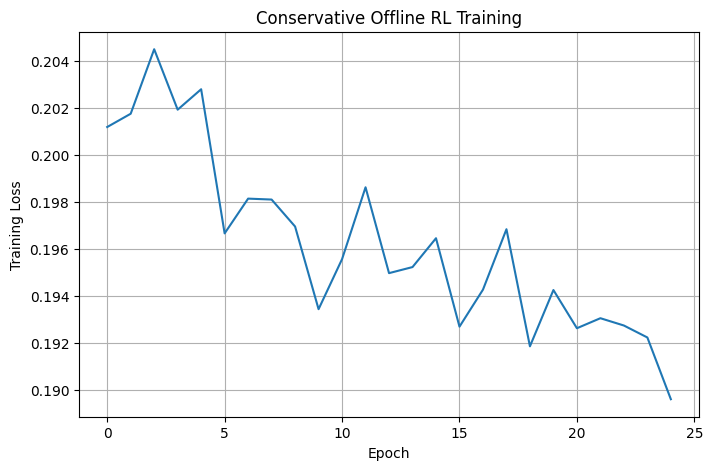

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")

plt.title(
    "Conservative Offline RL Training"
)

plt.grid(True)

plt.show()

Cell 14

In [ ]:
# =========================================================
# SAFETY STATISTICS
# =========================================================

safety_stats = df.groupby(
    "Frequency_Channel"
).agg({
    "Interference_Density": "mean",
    "Packet_Loss_Rate": "mean",
    "Packet_Collision_Rate": "mean",
    "Latency": "mean"
})

print(safety_stats)

safety_stats["Risk_Score"] = (
    safety_stats["Interference_Density"]
    + safety_stats["Packet_Loss_Rate"] / 100
    + safety_stats["Packet_Collision_Rate"] / 100
    + safety_stats["Latency"] / 200
)

print("\nSafety risk by channel:")

print(
    safety_stats["Risk_Score"]
    .sort_values()
)

                   Interference_Density  Packet_Loss_Rate  \
Frequency_Channel                                           
433                            0.499798          6.768349   
470                            0.495259          6.905274   
868                            0.501547          6.966117   
915                            0.502617          6.998987   
923                            0.508847          6.979624   

                   Packet_Collision_Rate     Latency  
Frequency_Channel                                     
433                            16.584560  102.208604  
470                            16.512336  102.249096  
868                            16.605148  100.964704  
915                            16.797363  102.850758  
923                            16.813574  101.598558  

Safety risk by channel:
Frequency_Channel
470    1.240680
868    1.242083
433    1.244370
923    1.254772
915    1.254834
Name: Risk_Score, dtype: float64


Cell 15

In [ ]:
# =========================================================
# TEST POLICY
# =========================================================

model.eval()

X_test = torch.tensor(
    X[test_idx],
    dtype=torch.float32
).to(device)

with torch.no_grad():

    q_test = model(
        X_test
    ).cpu().numpy()

# Select highest Q-value
predicted_actions = np.argmax(
    q_test,
    axis=1
)

predicted_channels = [
    action_to_channel[a]
    for a in predicted_actions
]

print("Example predictions:")

for i in range(10):

    print(
        f"Sample {i+1}: "
        f"Selected Channel = "
        f"{predicted_channels[i]}"
    )

Example predictions:
Sample 1: Selected Channel = 915
Sample 2: Selected Channel = 923
Sample 3: Selected Channel = 433
Sample 4: Selected Channel = 433
Sample 5: Selected Channel = 915
Sample 6: Selected Channel = 915
Sample 7: Selected Channel = 915
Sample 8: Selected Channel = 433
Sample 9: Selected Channel = 433
Sample 10: Selected Channel = 470


Cell 16

In [ ]:
# =========================================================
# SAFE POLICY
# =========================================================

risk_values = (
    safety_stats["Risk_Score"]
    .to_dict()
)

safe_threshold = (
    safety_stats["Risk_Score"]
    .quantile(0.75)
)

safe_channels = [
    ch
    for ch, risk in risk_values.items()
    if risk <= safe_threshold
]

print(
    "Safe channels according to "
    "historical risk:"
)

print(safe_channels)

safe_actions = [
    channel_to_action[ch]
    for ch in safe_channels
]

safe_predictions = []

for q in q_test:

    safe_q = q.copy()

    for action in range(action_size):

        if action not in safe_actions:

            safe_q[action] = -np.inf

    selected_action = np.argmax(
        safe_q
    )

    safe_predictions.append(
        action_to_channel[selected_action]
    )

print("\nExample SAFE decisions:")

for i in range(10):

    print(
        f"Sample {i+1}: "
        f"Channel = "
        f"{safe_predictions[i]}"
    )

Safe channels according to historical risk:
[433, 470, 868, 923]

Example SAFE decisions:
Sample 1: Channel = 433
Sample 2: Channel = 923
Sample 3: Channel = 433
Sample 4: Channel = 433
Sample 5: Channel = 923
Sample 6: Channel = 470
Sample 7: Channel = 433
Sample 8: Channel = 433
Sample 9: Channel = 433
Sample 10: Channel = 470


Cell 17

In [ ]:
# =========================================================
# POLICY COMPARISON
# =========================================================

test_df = df.iloc[test_idx].copy()

# Random policy
rng = np.random.default_rng(42)

random_channels = rng.choice(
    channels,
    size=len(test_df)
)

# Model policy
model_channels = predicted_channels

# Safe policy
cql_safe_channels = safe_predictions

# Historical reward by channel
channel_reward = (
    df.groupby("Frequency_Channel")
      ["Reward"]
      .mean()
      .to_dict()
)

def evaluate_policy(selected_channels):

    estimated_rewards = [
        channel_reward[ch]
        for ch in selected_channels
    ]

    return np.mean(
        estimated_rewards
    )


random_reward = evaluate_policy(
    random_channels
)

model_reward = evaluate_policy(
    model_channels
)

safe_reward = evaluate_policy(
    cql_safe_channels
)

print("==========================================")
print("       OFFLINE POLICY EVALUATION")
print("==========================================")

print(
    "Random Policy Reward:",
    round(random_reward, 4)
)

print(
    "DQN Policy Reward:",
    round(model_reward, 4)
)

print(
    "Conservative Safe RL Reward:",
    round(safe_reward, 4)
)

       OFFLINE POLICY EVALUATION
Random Policy Reward: 0.2176
DQN Policy Reward: 0.2176
Conservative Safe RL Reward: 0.2178


Cell 18

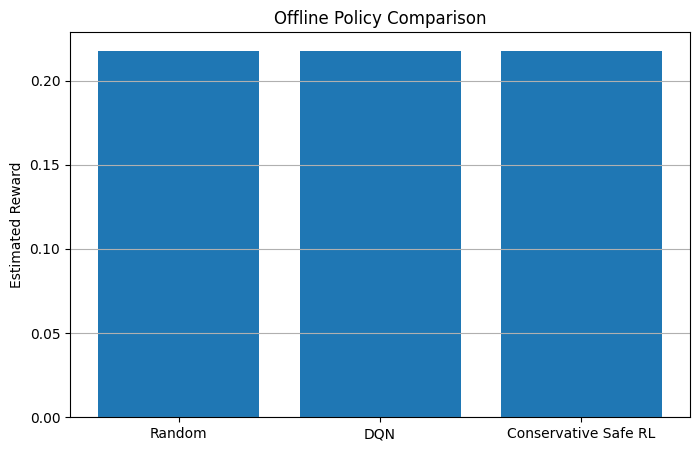

In [ ]:
policy_names = [
    "Random",
    "DQN",
    "Conservative Safe RL"
]

policy_rewards = [
    random_reward,
    model_reward,
    safe_reward
]

plt.figure(figsize=(8,5))

plt.bar(
    policy_names,
    policy_rewards
)

plt.ylabel("Estimated Reward")

plt.title(
    "Offline Policy Comparison"
)

plt.grid(
    axis="y"
)

plt.show()

Cell 19

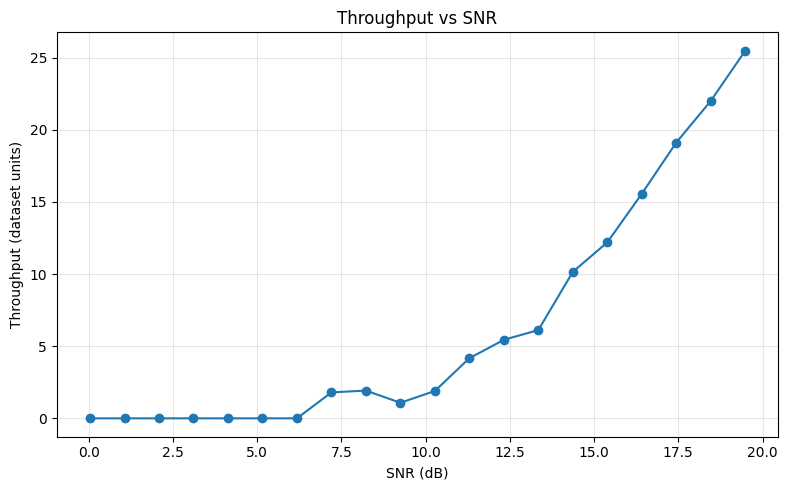

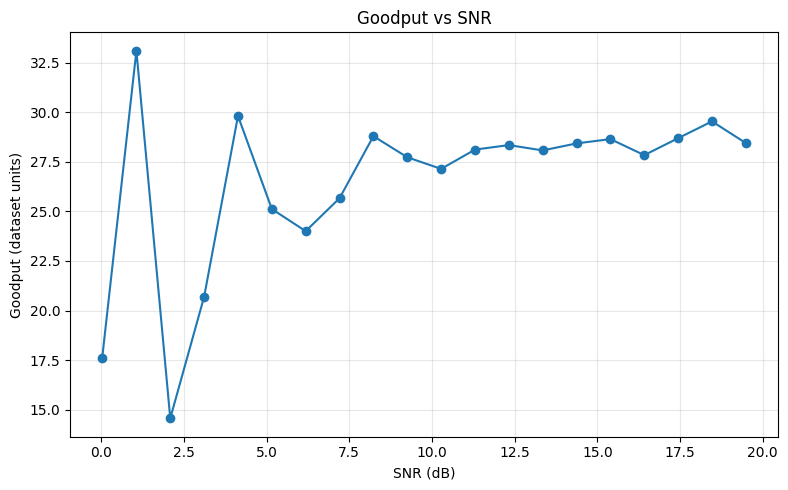

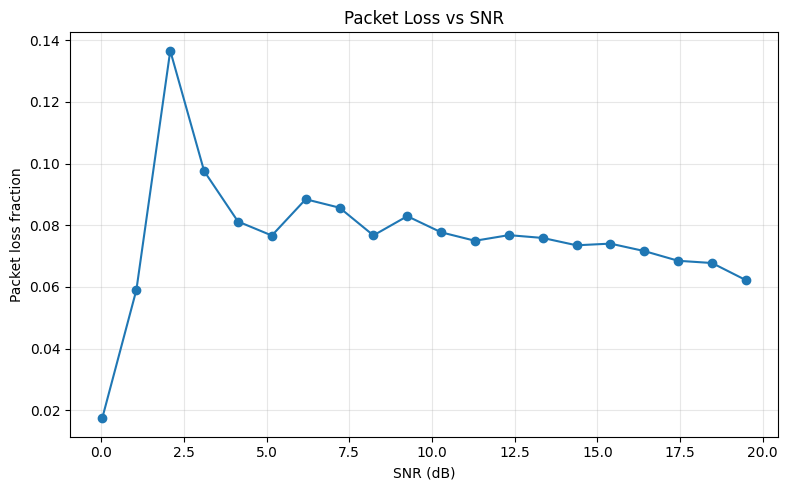

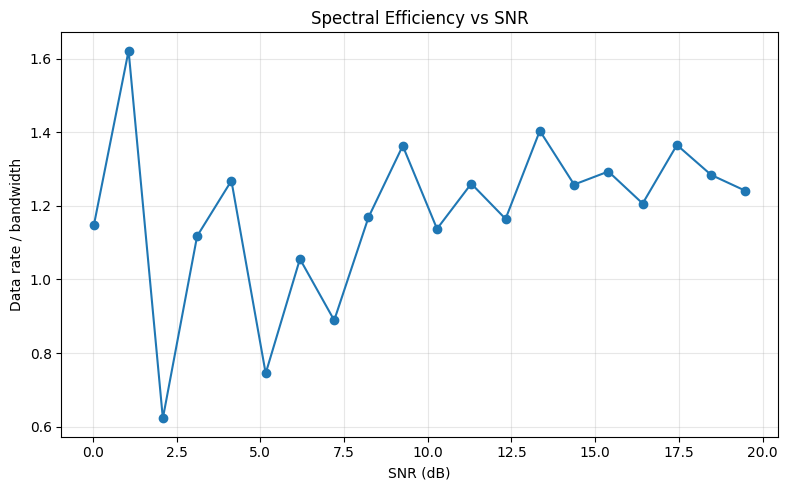

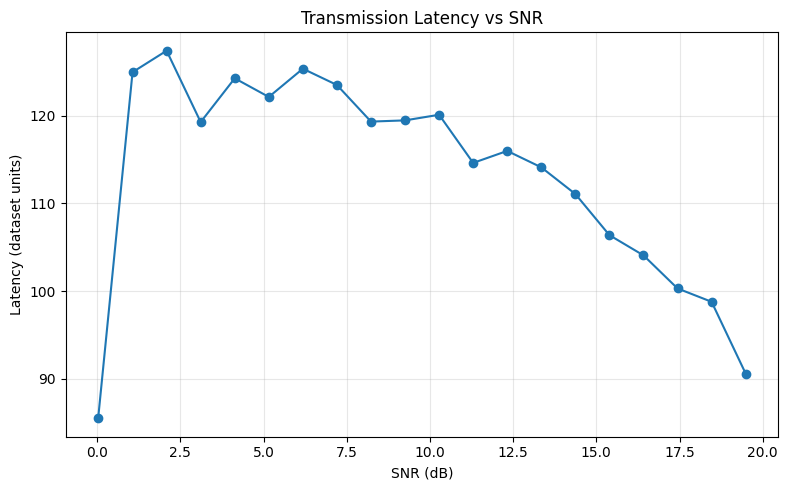

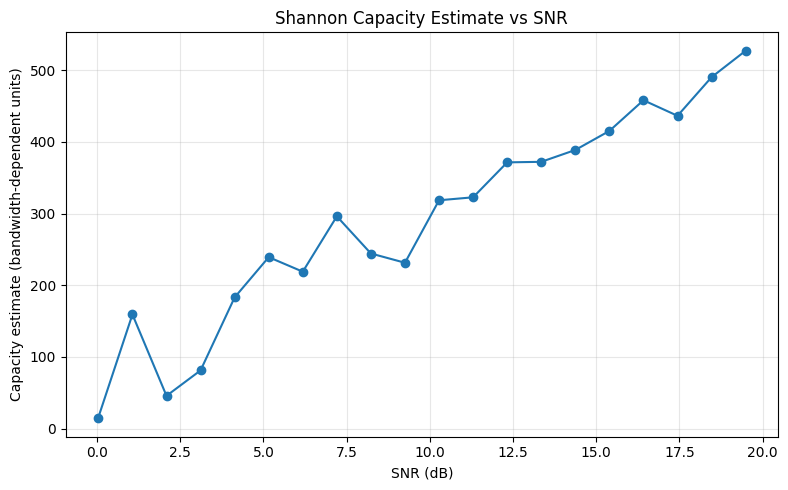

Wireless performance curves generated.


In [ ]:

# ============================================================
# WIRELESS COMMUNICATION PERFORMANCE CURVES
# X-AXIS: SNR (dB)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Check that the dataset is loaded
required = [
    "SNR", "Data_Rate", "Bandwidth", "Latency",
    "Packet_Loss_Rate", "Interference_Power",
    "Energy_Cost", "Delivery_Success"
]

missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(f"Missing dataset columns: {missing}")

# Create wireless performance metrics
data = df.copy()

data["Delivery_Success_Binary"] = (
    data["Delivery_Success"].astype(str).str.lower()
    .isin(["success", "1", "true"])
).astype(float)

loss = data["Packet_Loss_Rate"].astype(float)

# Convert percentage values to fractions if applicable
if loss.max() > 1:
    loss = loss / 100.0

data["Packet_Loss_Fraction"] = loss.clip(0, 1)

data["Throughput"] = (
    data["Data_Rate"] * data["Delivery_Success_Binary"]
)

data["Goodput"] = (
    data["Data_Rate"] * (1 - data["Packet_Loss_Fraction"])
)

data["Spectral_Efficiency"] = (
    data["Data_Rate"] / data["Bandwidth"].replace(0, np.nan)
)

data["Energy_Efficiency"] = (
    data["Throughput"] / data["Energy_Cost"].replace(0, np.nan)
)

# Theoretical Shannon capacity estimate.
# Assumes SNR is in dB and bandwidth is in Hz.
snr_linear = 10 ** (data["SNR"] / 10)

data["Shannon_Capacity_Estimate"] = (
    data["Bandwidth"] * np.log2(1 + snr_linear)
)

# Group nearby SNR measurements into bins for smoother curves
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=["SNR"])

data["SNR_Bin"] = pd.cut(
    data["SNR"],
    bins=20,
    duplicates="drop"
)

curve_metrics = [
    ("Throughput", "Throughput vs SNR",
     "Throughput (dataset units)"),
    ("Goodput", "Goodput vs SNR",
     "Goodput (dataset units)"),
    ("Packet_Loss_Fraction", "Packet Loss vs SNR",
     "Packet loss fraction"),
    ("Spectral_Efficiency", "Spectral Efficiency vs SNR",
     "Data rate / bandwidth"),
    ("Latency", "Transmission Latency vs SNR",
     "Latency (dataset units)"),
    ("Shannon_Capacity_Estimate", "Shannon Capacity Estimate vs SNR",
     "Capacity estimate (bandwidth-dependent units)")
]

for metric, title, ylabel in curve_metrics:

    curve = (
        data.groupby("SNR_Bin", observed=True)[metric]
        .mean()
        .dropna()
    )

    if len(curve) < 2:
        print(f"Not enough valid SNR data for: {title}")
        continue

    snr_midpoints = np.array([
        interval.mid for interval in curve.index
    ])

    plt.figure(figsize=(8, 5))
    plt.plot(snr_midpoints, curve.values, marker="o")
    plt.xlabel("SNR (dB)")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

print("Wireless performance curves generated.")


Cell 20

In [ ]:

# ============================================================
# FINAL WIRELESS COMMUNICATION PERFORMANCE TABLE
# ============================================================

summary = df.groupby("Frequency_Channel").agg(
    Mean_Latency=("Latency", "mean"),
    Mean_Jitter=("Jitter", "mean"),
    Mean_Data_Rate=("Data_Rate", "mean"),
    Mean_Throughput=("Throughput", "mean"),
    Mean_Goodput=("Goodput", "mean"),
    Mean_PER_Proxy=("PER_Proxy", "mean"),
    Mean_Reliability=("Reliability", "mean"),
    Mean_Spectral_Efficiency=("Spectral_Efficiency", "mean"),
    Mean_Energy_Efficiency=("Energy_Efficiency", "mean"),
    Mean_SNR=("SNR", "mean"),
    Mean_Interference=("Interference_Power", "mean"),
    Mean_Channel_Occupancy=("Channel_Occupancy", "mean"),
    Mean_Collision_Rate=("Packet_Collision_Rate", "mean"),
    Mean_Shannon_Capacity=("Shannon_Capacity_Estimate", "mean")
)

print("FINAL WIRELESS COMMUNICATION RESULTS BY CHANNEL")
display(summary.round(4))


FINAL WIRELESS COMMUNICATION RESULTS BY CHANNEL


,Mean_Latency,Mean_Jitter,Mean_Data_Rate,Mean_Throughput,Mean_Goodput,Mean_PER_Proxy,Mean_Reliability,Mean_Spectral_Efficiency,Mean_Energy_Efficiency,Mean_SNR,Mean_Interference,Mean_Channel_Occupancy,Mean_Collision_Rate,Mean_Shannon_Capacity
Frequency_Channel,,,,,,,,,,,,,,
433,102.2086,15.3771,30.5568,16.4629,28.4415,0.0677,0.9323,1.2297,5.7919,16.5151,-82.2963,50.9462,16.5846,444.8593
470,102.2491,15.2835,30.0129,16.5731,27.9240,0.0691,0.9309,1.2228,5.8036,16.4762,-81.7208,51.6677,16.5123,462.8155
868,100.9647,15.0763,29.8076,17.1761,27.7562,0.0697,0.9303,1.2112,6.0084,16.6373,-81.9825,51.0056,16.6051,438.1304
915,102.8508,15.1040,31.0712,16.9358,28.9128,0.0700,0.9300,1.2963,5.8783,16.4581,-82.3399,50.3122,16.7974,449.7504
923,101.5986,15.1150,31.0121,16.5795,28.8290,0.0698,0.9302,1.3290,5.8052,16.4932,-82.1126,50.2539,16.8136,432.7153
